# Assignment 07: A First Machine Learning SDM

## BIO597 Spatial Analysis of Biodiversity

Repeat the workflow from Lab 07 for a Maine amphibian species of your choice. Focus on understanding what the model learns and what its predictions mean. You may reuse code from the lab.

## Deliverable

Submit this notebook with your completed code, figures, and short written answers, plus a saved suitability raster. There is no need to tune model settings or compare additional algorithms.


## 1. Import packages and load the data

Run this notebook from `docs/assignments`. Import the packages used in Lab 07. Load the two supplied files and display species counts.


In [2]:
pip install rioxarray scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 105.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 95.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rioxarray]/4 [xarray]o]
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import the packages used in Lab 07.
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split


amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

# Display species counts.
amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

## 2. Choose your species

Choose a common species other than the wood frog, with at least 500 records. Keep records with coordinate uncertainty below 100 m, as in the lab.


In [4]:
target_species = "Pseudacris crucifer"

# Select your species and apply the uncertainty filter.
presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()


# Store the result as presence and print its record count.
print("Number of records:", len(presence))


Number of records: 1029


**Why did you choose this species?** Write one or two sentences.
There were enough data points and I love spring peepers
## 3. Keep all climate variables available

As in Lab 07, make a list called `climate_variables` containing `bio_1` through `bio_19`. We will choose the model predictors after preparing the modeling table.


In [5]:
# Create climate_variables and display these columns at your species' records.
climate_variables = ["bio_" + str(number) for number in range(1, 20)]

presence[climate_variables].head()


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
7,6.033667,12.406000,30.341421,1008.109314,26.004,-14.884,40.888000,1.446000,-5.662000,18.181999,-6.827333,1126.0,117.0,77.0,11.435465,314.0,244.0,295.0,256.0
15,7.499833,10.227667,27.609510,951.310608,25.848,-11.196,37.043999,3.229333,18.366667,19.057333,-4.544000,1155.0,120.0,79.0,13.698776,334.0,245.0,254.0,294.0
29,5.654500,11.792334,28.162813,1060.219482,26.100,-15.772,41.872002,1.019333,-6.686000,18.416000,-7.943334,1099.0,111.0,71.0,11.360600,304.0,232.0,283.0,255.0
58,6.012000,12.240000,29.499662,1031.210205,26.180,-15.312,41.492001,1.479333,-5.998667,18.380001,-7.231333,1141.0,107.0,72.0,9.757760,306.0,254.0,292.0,257.0
70,6.190166,10.291666,28.289352,928.378540,24.104,-12.276,36.380001,-2.726667,17.236666,17.236666,-5.690667,1196.0,121.0,77.0,14.983714,352.0,241.0,241.0,316.0


## 4. Prepare presence and background tables

Use the prepared climate values at the occurrence records directly, as in the revised lab. We do not need to match records to raster cells or join tables by coordinates.

The code below prepares the climate grid for background sampling and mapping. Each grid row is a cell, but each presence row is an occurrence record. Several presence records may therefore describe the same climate cell.


In [6]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()


,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


In [7]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()


Usable presence records: 1029


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
7,6.033667,12.406000,30.341421,1008.109314,26.004,-14.884,40.888000,1.446000,-5.662000,18.181999,-6.827333,1126.0,117.0,77.0,11.435465,314.0,244.0,295.0,256.0,1
15,7.499833,10.227667,27.609510,951.310608,25.848,-11.196,37.043999,3.229333,18.366667,19.057333,-4.544000,1155.0,120.0,79.0,13.698776,334.0,245.0,254.0,294.0,1
29,5.654500,11.792334,28.162813,1060.219482,26.100,-15.772,41.872002,1.019333,-6.686000,18.416000,-7.943334,1099.0,111.0,71.0,11.360600,304.0,232.0,283.0,255.0,1
58,6.012000,12.240000,29.499662,1031.210205,26.180,-15.312,41.492001,1.479333,-5.998667,18.380001,-7.231333,1141.0,107.0,72.0,9.757760,306.0,254.0,292.0,257.0,1
70,6.190166,10.291666,28.289352,928.378540,24.104,-12.276,36.380001,-2.726667,17.236666,17.236666,-5.690667,1196.0,121.0,77.0,14.983714,352.0,241.0,241.0,316.0,1


In [8]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()


observed
1    1029
0    1029
Name: count, dtype: int64

The missing-value cleanup keeps incomplete presence records out of both models. `random_state=597` makes the background sample repeatable. Background is sampled from the full valid grid, so it can include cells where the species has been recorded. It represents available environments, not confirmed absences.

## 5. Define predictors and response

Start with `features = ["bio_1"]`, annual mean temperature, to connect with last week's model. Set `X` to this predictor column and `y` to the `observed` labels. Only the selected climate columns belong in `X`; the background's coordinate columns are for mapping.


In [9]:
# Set features to bio_1 only.
# Define X and y, following Lab 07.
features = ["bio_1"]
X = model_data[features]
y = model_data["observed"]

X.head()

,bio_1
0,6.033667
1,7.499833
2,5.654500
3,6.012000
4,6.190166


## 6. Split, fit, and predict

Split `model_data` into `train_data` (75%) and `test_data` (25%) with `random_state=597``, as in the lab

Fit a `RandomForestRegressor` using only `bio_1`, with 100 trees, `min_samples_leaf=5`, and `random_state=597`.


In [10]:
# Split model_data into train_data and test_data. 9 in lab
# Define X_train, X_test, y_train, and y_test using features and observed.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))

Training cells: 1543
Test cells: 515


In [15]:
# Create model and fit it to the training data.

model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=597,
)
model.fit(X_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",597
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease 

In [18]:
# Predict suitability for X_test
test_prediction = model.predict(X_test)

## 7. Check the BIO1-only predictions

Calculate mean absolute error and store it as `bio1_error`. Plot test predictions for presence and background cells in overlapping histograms, as in the lab.


BIO1-only MAE: 0.279


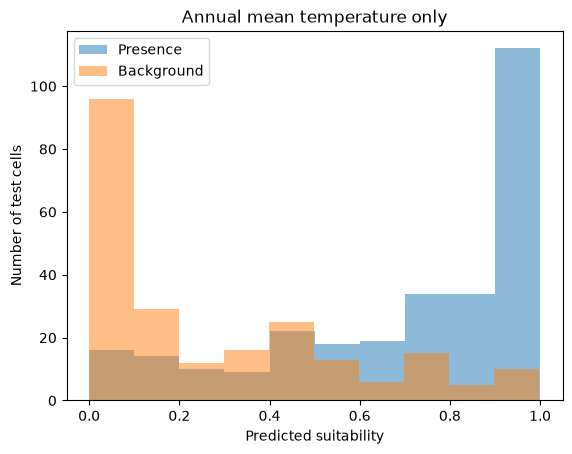

In [19]:
# Calculate and print bio1_error.
bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))
# Plot the predicted score distributions for the two test labels.
plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()

**Interpretation:** Do test presence cells generally receive higher scores? Why should we use withheld cells to check the model?
yes higher scores for prescence cells, don't want to overfit the model want it to generalize. The practice exam shouldnt be the same as the final

## 8. Add precipitation and compare MAE

Choose three new bioclim variables to test (you can look up the meanings of the variables
in the [bioclimatic variables documentation](https://www.worldclim.org/data/bioclim.html))

Change `features` to `["bio_X", "bio_XX", "bio_XX"]` (replacing the "X" values with the integer
index of the bioclim variables you chose). Create a new feature table (`X`) selecting just the features of interest and perform a new test/train split. Fit a new forest with these three predictors and calculate `three_variable_error`. Print both MAEs together.


In [21]:
# Select the three predictor columns from the existing training and test tables.
features = ["bio_2", "bio_12", "bio_16"]

# Fit three_variable_model and predict the same withheld cells.
X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

three_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

three_variable_model.fit(X_train, y_train)
three_variable_prediction = three_variable_model.predict(X_test)
three_variable_error = mean_absolute_error(y_test, three_variable_prediction)
# Calculate three_variable_error and print it beside bio1_error.
print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO2 + BIO12 + BIO16 MAE:", round(three_variable_error, 3))


BIO1-only MAE: 0.279
BIO2 + BIO12 + BIO16 MAE: 0.283


**Interpretation:** Did the three new bioclim variables improve prediction error for your species? Explain why the new conditions you chose may or may not be relevant biologically.

It did not improve the prediction error. I picked Mean Diurnal range, annual precip, and precip of wettest quarter. Overall my error was not that much worse than the first one, and becasue my chosen variables related ot temperature and precipitation I am not surprised it was not vastly different. 

## 9. Make a suitability map

Fit a new `final_model` using all modeling rows and the three predictors. Predict scores for `grid[features]`. Use the plotting recipe from Lab 07 to turn the suitability column into a raster and map it from 0 to 1.


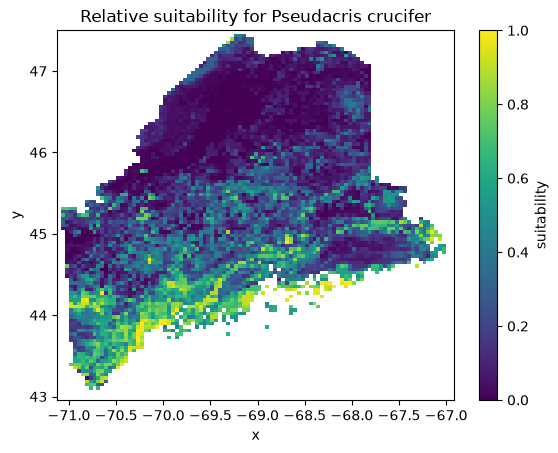

In [22]:
# Update X to include all three predictors.
X = model_data[features]
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)


# Fit final_model with the same forest settings.
final_model.fit(X, y)
# Add grid["suitability"], convert it to a raster named suitability, and plot it.
grid["suitability"] = final_model.predict(grid[features])
suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()

**Interpretation:** Which parts of Maine receive high scores? Why should we describe these as relative suitability rather than probability of occurrence?
The coast shows high scores, suitibility does not mean soemthign will occur there, there could be other biotic factors that effect where a species could be found such as competition and predation.

## 10. Plot variable importance

Use `final_model.feature_importances_` and `pd.Series()` as in the lab to make a bar plot for the three predictors.


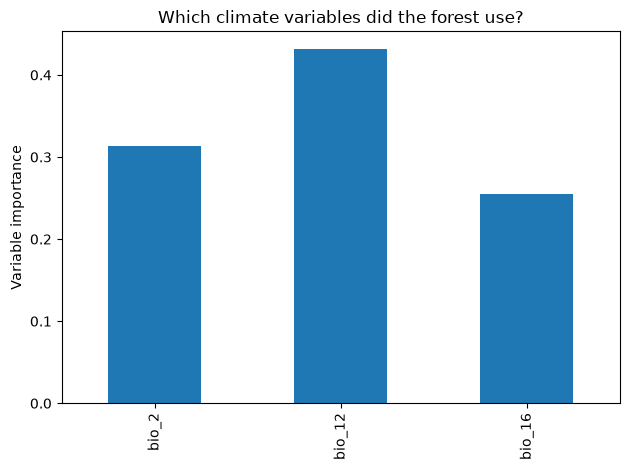

In [23]:
# Make and label a variable-importance plot.
importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()

**Interpretation:** Which variable did your forest use most? Give one reason why this does not establish an ecological cause.
Annual precip was used the most. This does not establish ecological casue becasue it is trained off correlation data and cannot speak to what causes a species to occur
## 11. Save your map

Save `suitability` as `Assignment07_suitability.tif` using the same CRS and export commands as the lab.


In [24]:
# Assign EPSG:4326 and save the suitability raster.
suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Assignment07_suitability.tif")

## 12. Run the training and prediction again including all 19 bioclim variables

**Think about:** Do you predict that more variables will improve the MAE of the model?

In [25]:
# Run the full analysis again but this time include all 19 bioclim variables
# feel free to copy/paste from cells above

features = ["bio_1", "bio_2","bio_3","bio_4","bio_5","bio_6","bio_7","bio_8","bio_9","bio_10","bio_11","bio_12","bio_13","bio_14","bio_15","bio_16","bio_17","bio_18", "bio_19"]

X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

all_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

all_variable_model.fit(X_train, y_train)
all_variable_prediction = all_variable_model.predict(X_test)
all_variable_error = mean_absolute_error(y_test, all_variable_prediction)


print("All Bioclim MAE:", round(all_variable_error, 3))


All Bioclim MAE: 0.258


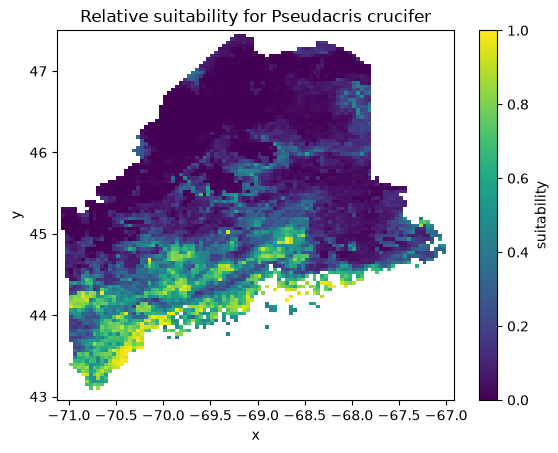

In [27]:
# Update X to include all  predictors.
X = model_data[features]
all_final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)


# Fit final_model with the same forest settings.
all_final_model.fit(X, y)
# Add grid["suitability"], convert it to a raster named suitability, and plot it.
grid["suitability"] = all_final_model.predict(grid[features])
suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()

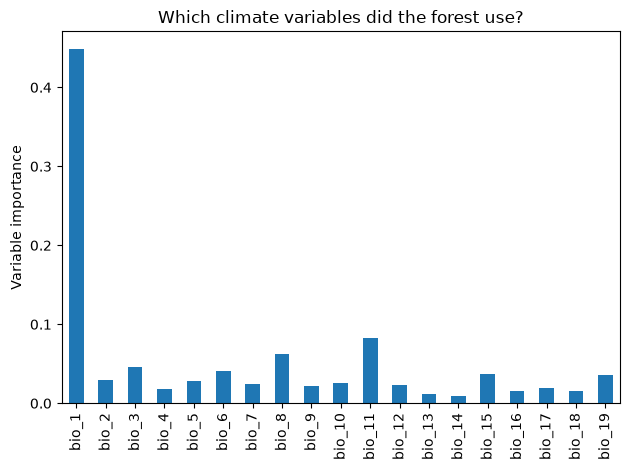

In [28]:
# Make and label a variable-importance plot.
importance = pd.Series(all_final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()

## Final reflection

Answer in two or three sentences per question.

1. How does this week's BIO1-only random forest differ from last week's hand-built temperature curve?
The bigges difference is that our model last week was built off an assumption we gave it, which was that the highest suitibility will be near the mean temp records. This week, the model was based on just the data. 
2. What did the comparison with three predictors teach you? Would you expect more predictors always to reduce test error?
I learned that adding more predictors does not always improve the model, it is important to understand what variables may be important for your system. 
3. Several presence records can share a climate cell. Why might a random split then make prediction look easier than predicting a new location?

4. Name one habitat variable or sampling issue missing from your model. How might it affect the map?
Time of year, if we were looking at the wettest quater precipitation, we would want to train it on occurance data found in the wettest quarter. 

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, written answers, both MAEs, and saved raster. Commit and push the notebook and raster to your class GitHub repository.

```bash
git add docs/assignments/Assignment-07-MachineLearningSDM.ipynb docs/assignments/Assignment07_suitability.tif
git commit -m "Complete machine learning SDM assignment"
git push
```
